In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression

from ics26_experiments import RESULTS_DIR

/home/prajwal/github-repos/knnsur/src/__init__.py:17: UserWarning: CuPy not available; GPU acceleration will be disabled.
  warnings.warn(msg)


In [ ]:
ICS26_DIR = RESULTS_DIR / "ics26"
for d in ICS26_DIR.iterdir():
    print(d.name)

adaptive_clustering_global_vs_local
adaptive_clustering_global_vs_n_init_clusters
adaptive_clustering_global_local_vs_min_pts_per_cluster
ellipsoidal_knn_containment
rosenbrock_convergence_no_containment
shifted_gaussians_no_q_shrink_global_error_scaling
shifted_gaussians_with_q_shrink_global_error_scaling
shifted_gaussians_with_identity_global_error_scaling
shifted_gaussians_with_pca_only_global_error_scaling
shifted_gaussians_with_ac_v1
quadratic_with_q_shrink
rosenbrock_convergence
quadratic_v1
quadratic_v1_hessian_informed_split_experiments


In [ ]:
# Publication-Quality Plot Settings
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.family": "serif",
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "figure.figsize": (6.5, 4.5),
        "figure.dpi": 100,
        "savefig.dpi": 300,
        "lines.linewidth": 1.5,
        "lines.markersize": 5,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.axisbelow": True,
    }
)
PALETTE = "deep"
COLORS = sns.color_palette(PALETTE)

# Quadratic (Old code - PCA / Hessian informed PCA)

In [ ]:
quadratic_dir = ICS26_DIR / "quadratic_v1_hessian_informed_split_experiments"
csv_path = quadratic_dir / "summary.csv"

df_q = pd.read_csv(csv_path)

In [8]:
df_q

,problem_name,problem_tag,tol,dim,n_train,n_test,n_clusters,max_rel_error_linf,max_rel_error_l2,median_rel_error_linf,...,CLUSTER_SPLITTING_METHOD,N_INIT_CLUSTERS,N_MIN_PER_CLUSTER,K_NEIGHBOURS,ENFORCE_CONTAINMENT,CONTAINMENT_LEVEL,Q_SHRINK,SYNTH_BUDGET_FACTOR,CLUSTERING_VERSION,USE_HESSIAN_INFORMED_SPLIT
0,Quadratic,2D_N100000_InitClust25_Tol0.1_ErrScaleglobal_M...,0.1000,2,100000,10000,25,0.003925,0.003925,0.001008,...,hessian_pca,25,100,1,False,1.0,0.05,1000,v1,True
1,Quadratic,2D_N100000_InitClust25_Tol0.1_ErrScaleglobal_M...,0.1000,2,100000,10000,25,0.003925,0.003925,0.001008,...,hessian_pca,25,100,1,False,1.0,0.05,1000,v1,False
2,Quadratic,2D_N100000_InitClust25_Tol0.05_ErrScaleglobal_...,0.0500,2,100000,10000,25,0.003925,0.003925,0.001008,...,hessian_pca,25,100,1,False,1.0,0.05,1000,v1,True
3,Quadratic,2D_N100000_InitClust25_Tol0.05_ErrScaleglobal_...,0.0500,2,100000,10000,25,0.003925,0.003925,0.001008,...,hessian_pca,25,100,1,False,1.0,0.05,1000,v1,False
4,Quadratic,2D_N100000_InitClust25_Tol0.02_ErrScaleglobal_...,0.0200,2,100000,10000,25,0.003925,0.003925,0.001008,...,hessian_pca,25,100,1,False,1.0,0.05,1000,v1,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69,Quadratic,5D_N100000_InitClust25_Tol0.002_ErrScaleglobal...,0.0020,5,100000,10000,7779,0.008430,0.008430,0.001904,...,hessian_pca,25,100,1,False,1.0,0.05,1000,v1,False
70,Quadratic,5D_N100000_InitClust25_Tol0.001_ErrScaleglobal...,0.0010,5,100000,10000,21557,0.005592,0.005592,0.001235,...,hessian_pca,25,100,1,False,1.0,0.05,1000,v1,True
71,Quadratic,5D_N100000_InitClust25_Tol0.001_ErrScaleglobal...,0.0010,5,100000,10000,21557,0.005592,0.005592,0.001235,...,hessian_pca,25,100,1,False,1.0,0.05,1000,v1,False
72,Quadratic,5D_N100000_InitClust25_Tol0.0005_ErrScalegloba...,0.0005,5,100000,10000,54657,0.002549,0.002549,0.000770,...,hessian_pca,25,100,1,False,1.0,0.05,1000,v1,True


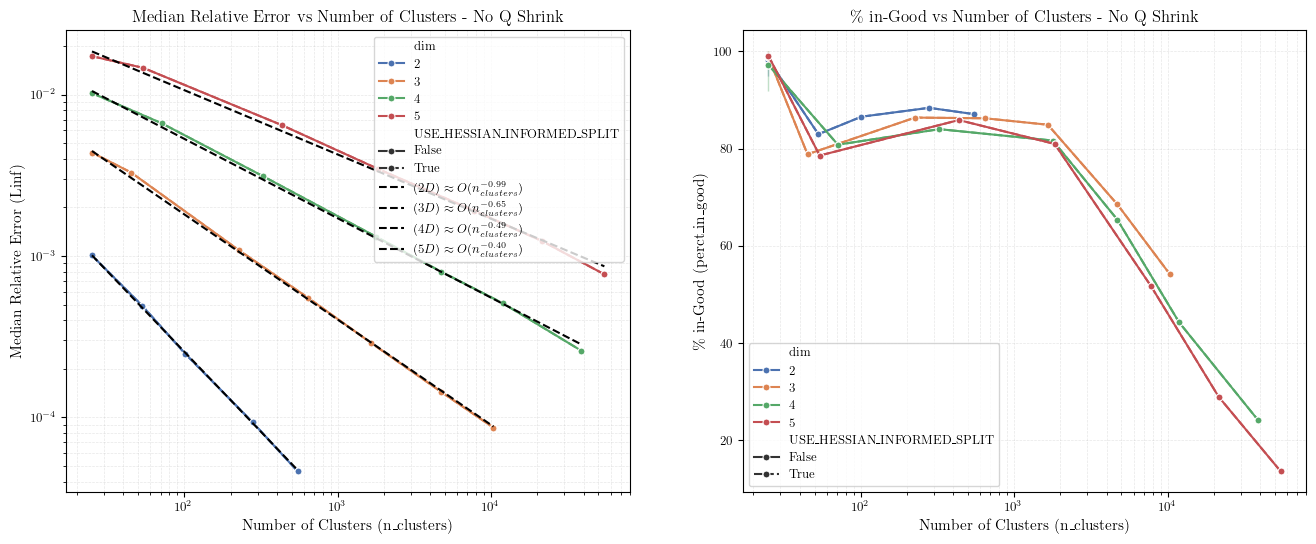

In [ ]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_q,
    x="n_clusters",
    y="median_rel_error_linf",
    hue="dim",
    style="USE_HESSIAN_INFORMED_SPLIT",
    marker="o",
    palette=PALETTE,
)
# Fit linear regression lines (in log-log space) for each dimension
for dim in df_q["dim"].unique():
    subset = df_q[df_q["dim"] == dim]
    X = np.log(subset["n_clusters"].values).reshape(-1, 1)
    y = np.log(subset["median_rel_error_linf"].values)
    # Drop the last point to avoid outlier influence
    X = X[:-1]
    y = y[:-1]
    model = LinearRegression()
    model.fit(X, y)
    x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
    y_fit = model.predict(x_fit)
    label = rf"$({dim}D) \approx O(n_{{clusters}}^{{{model.coef_[0]:.2f}}})$"
    plt.plot(np.exp(x_fit), np.exp(y_fit), linestyle="--", color="k", label=label)
plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of Clusters (n_clusters)")
plt.ylabel("Median Relative Error (Linf)")
plt.title("Median Relative Error vs Number of Clusters - No Q Shrink")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_q,
    x="n_clusters",
    y="perct_in_good",
    hue="dim",
    style="USE_HESSIAN_INFORMED_SPLIT",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.xlabel("Number of Clusters (n_clusters)")
plt.ylabel(r"$\%$ in-Good (perct_in_good)")
plt.title(r"$\%$ in-Good vs Number of Clusters - No Q Shrink")
plt.grid(True, which="both", ls="--", lw=0.5)